In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd
import io

### Parameters dictionary
- parameters are written in exported ppt file

In [ ]:
parameters = dict()

parameters['ms filepath'] = 'sample_data/flowmod_C2C005_QTOF.mzML'
parameters['sample'] = 'C2C005'
parameters['modulation time'] = 4

### Load data file

In [33]:
ms_data = c2c.load_file(parameters['ms filepath'])
ms_data.getBPC()

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
110000
120000
130000
140000
150000
160000
170000
180000
190000
200000
210000
220000
230000
240000
250000
260000
270000
280000
Number of MS1 scans: 284354


### Find intensity cut-off for MS scans

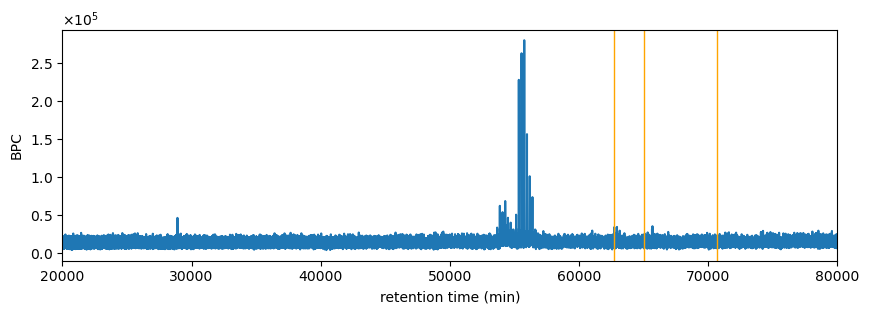

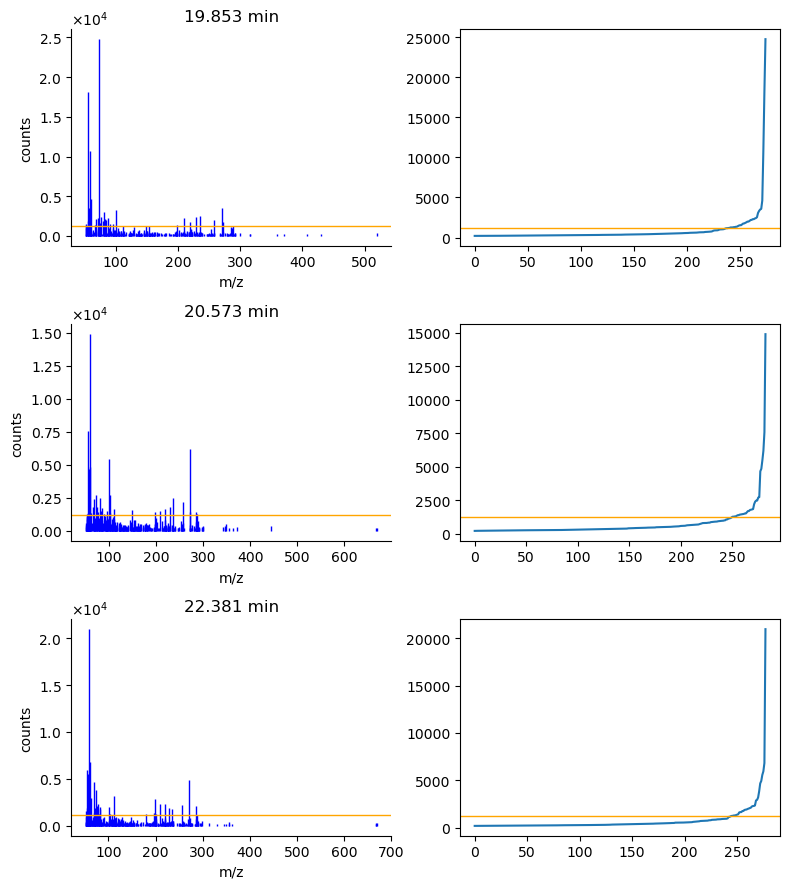

In [37]:
idx_list = [62725, 65000, 70713] # scan numbers to plot
parameters['scan inty cutoff'] = 1200

tic_fig, tic_ax = plt.subplots(figsize=(10, 3))

tic_ax.plot(range(len(ms_data.rt)), ms_data.bpc)
tic_ax.set_xlabel('retention time (min)')
tic_ax.set_ylabel('BPC')
tic_ax.ticklabel_format(style='sci', useMathText=True, scilimits=(0, 3), axis='y')
tic_ax.set_xlim(20000, 80000)

fig, ax = plt.subplots(len(idx_list), 2, figsize=(8, len(idx_list) * 3))

for i, idx in enumerate(idx_list):
    tic_ax.axvline(x=idx, color='orange', lw=1)
    ms_data.MS1Data[idx].plotScan(ax[i, 0], annotation = False)
    ax[i, 0].spines['top'].set_visible(False)
    ax[i, 0].spines['right'].set_visible(False)
    ax[i, 0].axhline(y=parameters['scan inty cutoff'], color='orange', lw=1)

    ax[i, 1].plot(range(len(ms_data.MS1Data[idx].intensity)), sorted(ms_data.MS1Data[idx].intensity))
    ax[i, 1].axhline(y=parameters['scan inty cutoff'], color='orange', lw=1)

plt.tight_layout()
plt.show()

In [38]:
# go through all MS scans and remove m/z under cut-off. Refreshes TIC and BPC
ms_data.intyCutoff(cutoff=parameters['scan inty cutoff'])

Refreshing TIC and BPC...


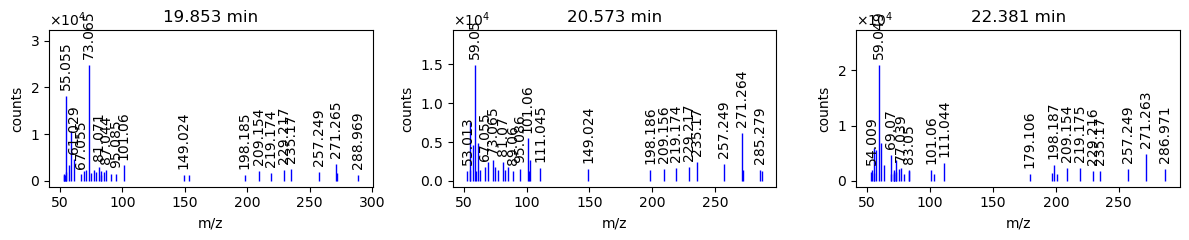

In [39]:
# plot scans from above after intensity cut-off
fig, ax = plt.subplots(1, len(idx_list), figsize= (len(idx_list) * 4, 2.5))

for i, idx in enumerate(idx_list):

    ms_data.MS1Data[idx].plotScan(ax[i], annotation=True) #annotation_dict=dict({'mz range': (40, 700), 
                                                                               #'mz diff': 10,
                                                                               #'threshold': 1e4}))

plt.tight_layout()
plt.show()

### Load FID data (for Agilent FID with CSV files)

In [ ]:
fid = pd.read_csv('sample_data/flowmod_C2C005_FID.csv', sep=',', names=['RT', 'FID'])
fid.head()

,RT,FID
0,0.000326,2.407383
1,0.000659,2.407063
2,0.000993,2.405869
3,0.001326,2.404210
4,0.001659,2.402816


### Check, if FID and MS data have same retention time

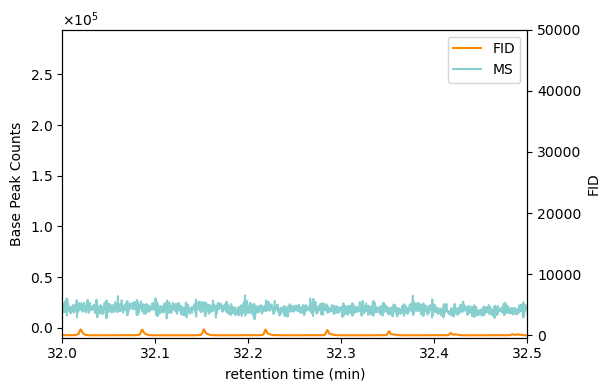

In [ ]:
fig, ax = plt.subplots(figsize = (6, 4))
ax_fid = ax.twinx()

p_fid, = ax_fid.plot(fid['RT'].values, fid['FID'].values, color='#ff8800', label='FID')
p_ms, = ax.plot(ms_data.rt, ms_data.bpc, color='#00999977', label='MS') #if bpc does not show clear signal try bpcx with excluded background masses

ax.legend(handles=[p_fid, p_ms])
ax_fid.set_ylim(-400, 50000)
# ax.set_ylim(5e4, 6e5)
ax.set_xlim(32, 32.5)
ax.set_ylabel('Base Peak Counts')
ax_fid.set_ylabel('FID')
ax.set_xlabel('retention time (min)')
ax.ticklabel_format(style='sci', useMathText=True, scilimits=(0, 3), axis='y')

plt.show()

### Start ChromAnalyzer
- pick signals from FID or MS data
- combine them with respect to modulation time
- remove peaks with low intensity
- get 2d RT
- integrate MS1 scans
- export as csv and pptx

In [42]:
data_analysis = c2c.ChromAnalyzer(fid['RT'], fid['FID'], msfile=ms_data) # get chromatogram from fid and qtof scans from ms data

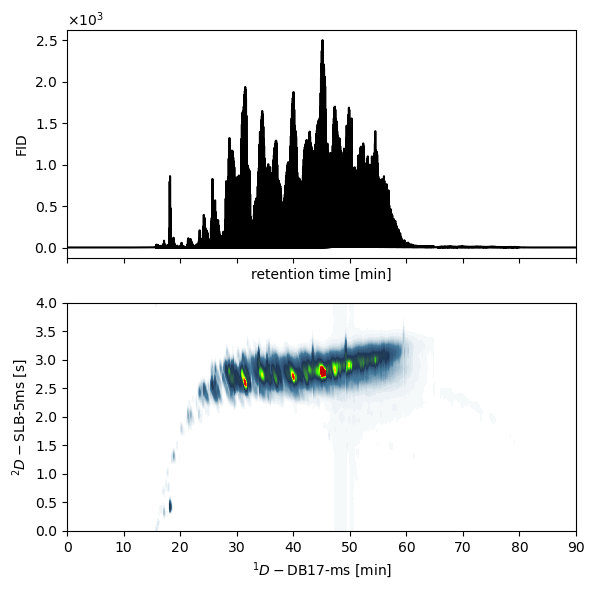

In [44]:
# 1D and 2D plots with TIC
parameters['shift'] = 1.5
parameters['solvent cut'] = 0

xmin = 0
xmax = 90

fig, ax = plt.subplots(2, figsize=(6, 6), sharex=True)

c2c.plot1d(ax[0], fid['RT'], fid['FID'], linecolor='black')
c2c.plot2d(fig, ax[1], fid['RT'].values, fid['FID'].values, mod_time=parameters['modulation time'], 
           shift=parameters['shift'], color_range=(0, 80), cbar=False,
           axis_labels=('DB17-ms', 'SLB-5ms'), solvent_cut=parameters['solvent cut'])

ax[0].set_ylabel('FID')
ax[0].ticklabel_format(style='sci', scilimits = (0, 3), useMathText=True, axis='y')
ax[0].set_xlim(xmin, xmax)
ax[1].set_xlim(xmin, xmax)

plt.tight_layout()

# save image for report later
chromatogram_img = io.BytesIO()
plt.savefig(chromatogram_img)
plt.show()

#### pick signals

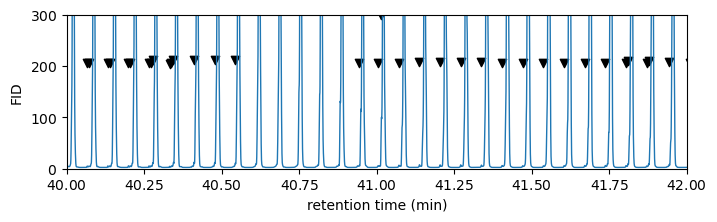

In [50]:
xmin = 40
xmax = 42
ymin = 0
ymax = 3e2

parameters['prominence'] = 1
parameters['minimum peak height'] = 3
 
fig, ax = plt.subplots(figsize=(8, 2))

data_analysis.pickSignals(ax, prominence=parameters['prominence'], 
                          height=parameters['minimum peak height'], 
                          solvent_cut=parameters['solvent cut'], 
                          marker_offset=200)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_ylabel('FID')
ax.set_title('')

signals_img = io.BytesIO()
plt.savefig(signals_img)

plt.show()

In [51]:
# sample rate of QToF and FID are not the same. After peak picking we have index of FID data
# we need to change to index of MS data with use of retention time
display(data_analysis.picked_signals.head())
data_analysis.changeIndexToScan()
display(data_analysis.picked_signals.head()) 

,Time,Height,Peak index
0,15.574993,4.056848,46724
1,15.641993,13.147344,46925
2,15.708993,30.353732,47126
3,15.775659,37.307947,47326
4,15.842326,30.188323,47526


,Time,Height,Peak index
0,15.574993,4.056848,49209
1,15.641993,13.147344,49420
2,15.708993,30.353732,49632
3,15.775659,37.307947,49843
4,15.842326,30.188323,50053


#### combine signals

In [52]:
parameters['modulation time tolerance'] = 0.25

data_analysis.timeCluster(modtime=parameters['modulation time'], 
                          time_tol=parameters['modulation time tolerance']) # modulation time and time tolerance in seconds!
data_analysis.combineSignals(modtime=parameters['modulation time'], 
                             shift=parameters['shift'])

print('Number of combined features: %i' % len(data_analysis.combined_signals))

Number of combined features: 255


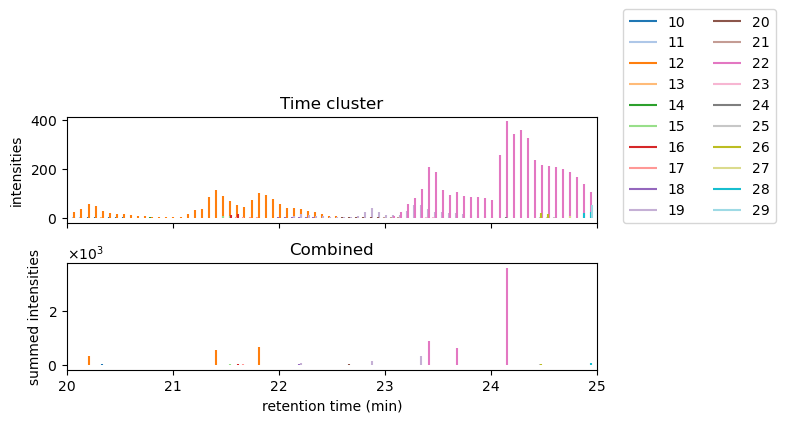

In [53]:
data_analysis.plotCluster(xmin=20, xmax=25)

#### remove peaks with low intensities

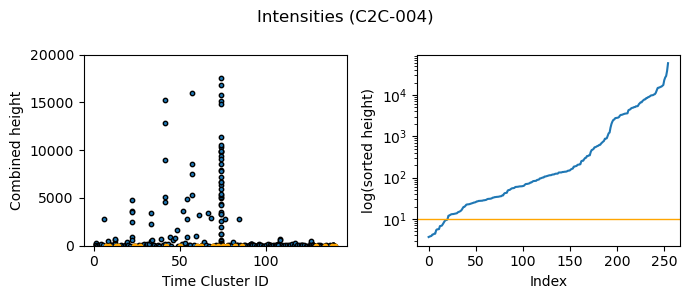

In [54]:
parameters['peak inty threshold'] = 10

fig, ax = plt.subplots(1, 2, figsize=(7, 3))

ax[0].scatter(data_analysis.combined_signals['Time Cluster ID'], data_analysis.combined_signals['Height'],
           s= 10, edgecolors='black')

ax[0].set_ylabel('Combined height')
ax[0].set_xlabel('Time Cluster ID')

removed = data_analysis.combined_signals[data_analysis.combined_signals['Height'] <= parameters['peak inty threshold']]
features = data_analysis.combined_signals[data_analysis.combined_signals['Height'] > parameters['peak inty threshold']]

ax[0].scatter(removed['Time Cluster ID'], removed['Height'], s= 10, c='orange')

ax[1].plot(sorted(data_analysis.combined_signals['Height']))
ax[1].axhline(y=parameters['peak inty threshold'], color='orange', linewidth = 1)
ax[1].set_yscale('log')
ax[1].set_ylabel('log(sorted height)')
ax[1].set_xlabel('Index')

ax[0].set_ylim(0, 2e4)

fig.suptitle('Intensities (%s)' %parameters['sample'])

plt.tight_layout()
lowInty_img = io.BytesIO()
plt.savefig(lowInty_img)
plt.show()

In [55]:
# integration of QToF data uses m/z clustering before to lower the resolution
# takes some minutes
data_analysis.integrateMSScans(simplify=True, mz_tol_fixed=0.05, mz_tol_ppm=50)

# use follwing function instead if Quadrupol data
# data_analysis.integrateMSScans(simplify=False)

data_analysis.results.head()

0
20
40
60
80
100
120


,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0


In [ ]:
# create ppt report with parameters and MS scans
c2c.exportMSScans(data_analysis.results, 
                  ppt_fout='sample_data/FLOW_C2C-005_MSScans.pptx',
                  parameters=parameters,
                  img_list=[chromatogram_img, signals_img, lowInty_img])

### Plot with cluster ID

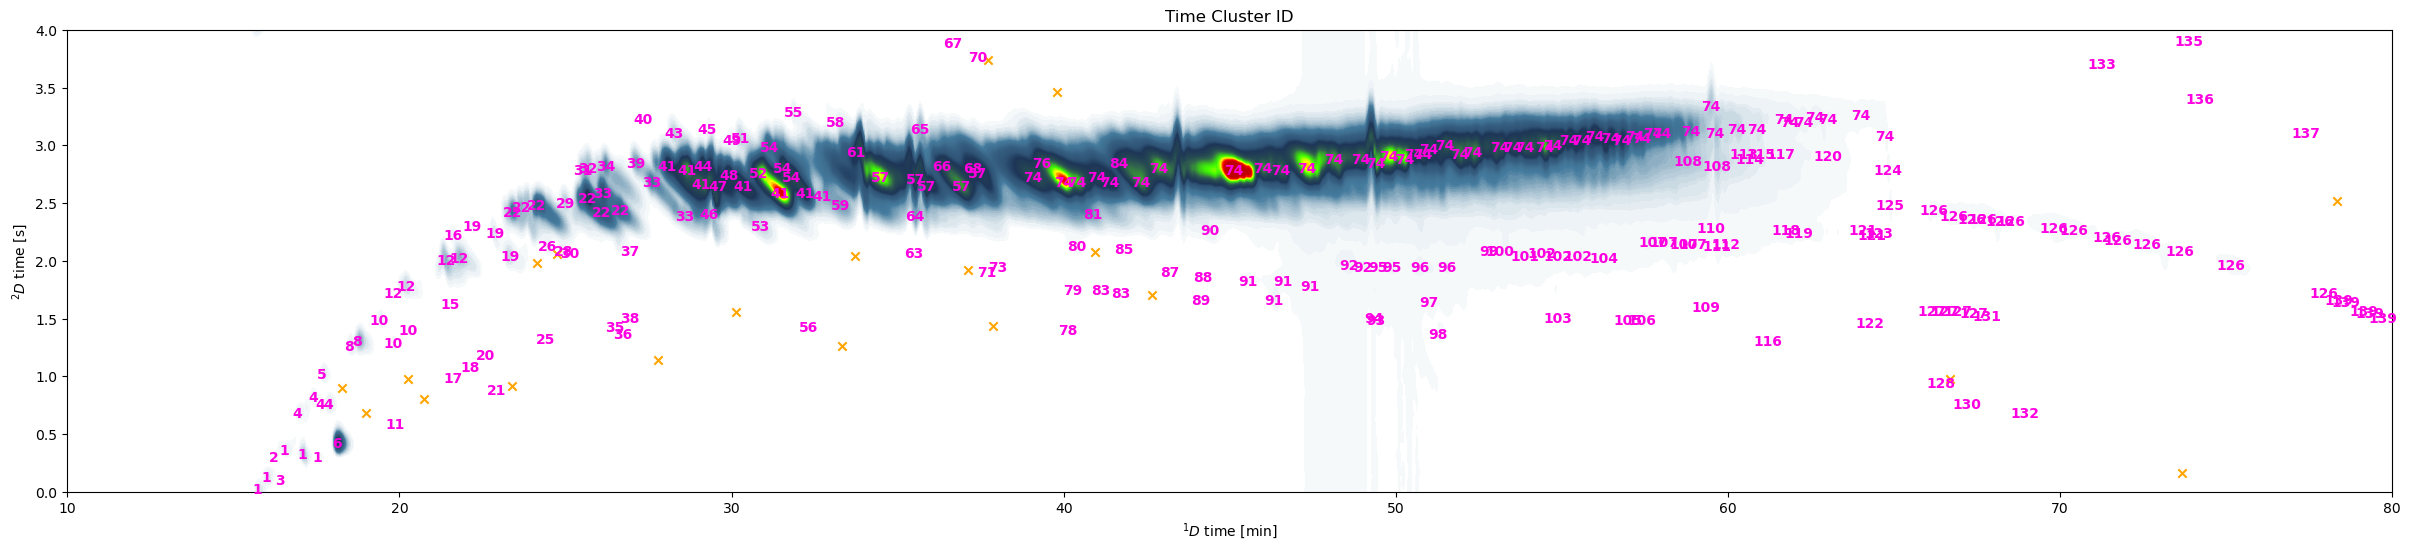

In [57]:
xmin = 10
xmax = 80

ymin = 0
ymax = 4

fig, ax = plt.subplots(figsize=(30, 6))

c2c.plot2d(fig, ax, fid['RT'].values, fid['FID'].values, 4, shift=parameters['shift'], cbar=False, color_range=(0, 80))

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

peaks = data_analysis.results[data_analysis.results['Height'] >= parameters['peak inty threshold']]
removed = data_analysis.results[data_analysis.results['Height'] < parameters['peak inty threshold']]

ax.scatter(removed['RT 1d (min)'], removed['RT 2d (s)'], marker='x', color='orange')
ax.set_title('Time Cluster ID')

for k in range(len(peaks)):
    rt1 = peaks.loc[peaks.index[k], 'RT 1d (min)']
    rt2 = peaks.loc[peaks.index[k], 'RT 2d (s)']
    if xmin <= rt1 <= xmax and ymin <= rt2 <= ymax:
        ax.text(rt1, rt2, 
                s=peaks.loc[peaks.index[k], 'Time Cluster ID'],
                va = 'center', ha='center', color="#FF00E1", fontdict=dict({'fontweight': 'bold'}))

plt.show()

In [ ]:
# save combined features which are not removed because of low intensity
peaks.to_csv('sample_data/Flow_C2C-005_MSscans.csv', sep=',', index=False)